# HW01: PyTorch를 활용한 모델 아키텍처 구현
**202302731 바이오메디컬공학부 류지윤**


> **과제 목적:** PyTorch를 사용하여 사용자 정의 모델 아키텍처를 직접 설계하고 구현하며 프레임워크 숙련도를 높인다.

## Initial Setup

런타임 유형을 GPU T4로 변경하고 필요한 라이브러리를 설치한다.

In [ ]:
!pip install pandas scikit-learn scipy torch numpy matplotlib

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

print(f"PyTorch 버전: {torch.__version__}")
print(f"CUDA 사용 가능 여부: {torch.cuda.is_available()}")
if torch.cuda.is_available():
  print(f"GPU 이름: {torch.cuda.get_device_name(0)}")

PyTorch 버전: 2.10.0+cu128
CUDA 사용 가능 여부: True
GPU 이름: Tesla T4


# Part 1: 데이터 준비

Google Colab에 내장된 California Housing 데이터셋을 사용한다.

*   **입력 (X)**: 8개의 피처(longitude, latitude, housing_median_age, ...)
*   **출력 (y)**: median_house_value(집값 중간 값)

학습에 앞서 반드시 해야 하는 것:

1.  **Train / Validation / Test 분할** - 모델 성능을 정확히 평가하기 위해
2.  **데이터 정규화(Normalization)** - 학습 안정성을 위해 (열 별로)


In [ ]:
# CSV 파일 불러오기
train_df = pd.read_csv('sample_data/california_housing_train.csv')
test_df  = pd.read_csv('sample_data/california_housing_test.csv')

print(f"Train 데이터: {train_df.shape}")
print(f"Test 데이터: {test_df.shape}")
print(f"\n컬럼 목록: {list(train_df.columns)}")
train_df.head()

Train 데이터: (17000, 9)
Test 데이터: (3000, 9)

컬럼 목록: ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'median_house_value']


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
0,-114.31,34.19,15.0,5612.0,1283.0,1015.0,472.0,1.4936,66900.0
1,-114.47,34.40,19.0,7650.0,1901.0,1129.0,463.0,1.8200,80100.0
2,-114.56,33.69,17.0,720.0,174.0,333.0,117.0,1.6509,85700.0
3,-114.57,33.64,14.0,1501.0,337.0,515.0,226.0,3.1917,73400.0
4,-114.57,33.57,20.0,1454.0,326.0,624.0,262.0,1.9250,65500.0


In [ ]:
# 피처(X)와 타겟(y) 분리
X_full = train_df.iloc[:, :-1].values # (17000, 8)
y_full = train_df.iloc[:,-1].values   # (17000,)

X_test = test_df.iloc[:, :-1].values # (3000, 8)
y_test = test_df.iloc[:,-1].values    # (3000,)

# Train / Validation 분할 (80%, 20%)
X_train, X_val, y_train, y_val = train_test_split(
    X_full, y_full, test_size=0.2, random_state=42
)

print(f"Train: {X_train.shape[0]}")
print(f"Validation: {X_val.shape[0]}")
print(f"Test: {X_test.shape[0]}")

Train: 13600
Validation: 3400
Test: 3000


### 왜 정규화가 필요한가?

타겟값(median_house_value)이 66,900 ~ 500,001 범위이기 때문에 정규화 없이 학습하면 Loss가 매우 커질 수 있다.

**StandardScaler**를 사용하면 평균=0, 표준편차=1로 변환되어 학습이 안정된다.

**중요**: `fit()`은 Train 데이터에서만! Val/Test에는 `transform()`만 적용한다.


In [ ]:
# StandardScaler 정규화 (Train에서 fit, Val/Test에서는 transform만)
scaler_X = StandardScaler()
X_train = scaler_X.fit_transform(X_train)
X_val = scaler_X.transform(X_val)
X_test = scaler_X.transform(X_test)

scaler_y = StandardScaler()
y_train = scaler_y.fit_transform(y_train.reshape(-1, 1)).flatten()
y_val = scaler_y.transform(y_val.reshape(-1,1)).flatten()
y_test = scaler_y.transform(y_test.reshape(-1,1)).flatten()

print(f"정규화 후 X_train 평균: {X_train.mean(axis=0).round(4)}")
print(f"정규화 후 y_train 평균: {y_train.mean():.4f}, 표준편차: {y_train.std():.4f}")

정규화 후 X_train 평균: [ 0. -0. -0.  0. -0.  0. -0. -0.]
정규화 후 y_train 평균: -0.0000, 표준편차: 1.0000


In [ ]:
# Numpy -> PyTorch Tensor 변환
X_train_pt = torch.tensor(X_train, dtype=torch.float32)
y_train_pt = torch.tensor(y_train, dtype=torch.float32)
X_val_pt   = torch.tensor(X_val,   dtype=torch.float32)
y_val_pt   = torch.tensor(y_val,   dtype=torch.float32)
X_test_pt  = torch.tensor(X_test,  dtype=torch.float32)
y_test_pt  = torch.tensor(y_test,  dtype=torch.float32)

print(f"X_train 텐서: {X_train_pt.shape}, dtype={X_train_pt.dtype}")
print(f"y_train 텐서: {y_train_pt.shape}, dtype={y_train_pt.dtype}")

X_train 텐서: torch.Size([13600, 8]), dtype=torch.float32
y_train 텐서: torch.Size([13600]), dtype=torch.float32


# Part 2: Dataset & DataLoader

*   **Dataset**: 데이터를 인덱스로 접근하는 클래스 (`__init__`,`__getitem__`, `__len__`)
*   **collate_fn**: 여러 개의 데이터 인스턴스를 하나의 배치로 합치는 함수
*   **DataLoader**: Dataset에서 미니배치를 자동으로 만들어주는 도구


In [ ]:
class CustomDataset(Dataset):
  def __init__(self, X, y, use_gpu):
    if use_gpu and torch.cuda.is_available():
      self.device_type = torch.device('cuda')
    else:
      self.device_type = torch.device('cpu')

    self.dataset_X = X
    self.dataset_y = y

  def __getitem__(self, idx):
    X = self.dataset_X[idx,:].to(self.device_type)
    y = self.dataset_y[idx].to(self.device_type)
    return dict(X=X, y=y)

  def __len__(self):
    return self.dataset_X.size(0)


In [ ]:
def collate_fn(batch):
   # batch = [{'X': tensor, 'y': tensor}, {'X': tensor, 'y': tensor}, ...]
   X = [b['X'].view(1,-1) for b in batch]
   X = torch.cat(X, dim=0)

   y = [b['y'] for b in batch]
   y = torch.stack(y)

   return dict(X=X, y=y)


In [ ]:
BATCH_SIZE = 64

# Train / Val / Test 각각의 Dataset과 DataLoader 생성
train_dataset = CustomDataset(X_train_pt, y_train_pt, use_gpu=True)
val_dataset = CustomDataset(X_val_pt, y_val_pt, use_gpu=True)
test_dataset = CustomDataset(X_test_pt, y_test_pt, use_gpu=True)

train_dataloader = DataLoader(dataset=train_dataset, collate_fn=collate_fn, batch_size=BATCH_SIZE, shuffle=True)
val_dataloader = DataLoader(dataset=val_dataset, collate_fn=collate_fn, batch_size=BATCH_SIZE, shuffle=False) # Validation은 셔플할 필요 없음
test_dataloader = DataLoader(dataset=test_dataset, collate_fn=collate_fn, batch_size=BATCH_SIZE, shuffle=False) # Test도 셔플할 필요 없음

print(f"Train 배치 수: {len(train_dataloader)} (데이터 {len(train_dataset)}개 / batch_size {BATCH_SIZE})")
print(f"Val   배치 수: {len(val_dataloader)}")
print(f"Test  배치 수: {len(test_dataloader)}")

Train 배치 수: 213 (데이터 13600개 / batch_size 64)
Val   배치 수: 54
Test  배치 수: 47


# Part 3: Custom Network (nn.Module)

`nn.Module`을 상속 받아 나만의 네트워크를 만듭니다.
활성화 함수를 인자로 받도록 설계하여, 다양한 활성화 함수를 쉽게 교체할 수 있도록 한다.

### 수학적 표현 & 텐서 Shape

우리가 만들 네트워크는 아래의 구조를 갖는다.

$$X \in \mathbb{R}^{n \times d} \xrightarrow{\text{Linear}_0} H \in \mathbb{R}^{n \times h} \xrightarrow{\sigma(\cdot)} Z \in \mathbb{R}^{n \times h} \xrightarrow{\text{Linear}_1} \hat{y} \in \mathbb{R}^{n}$$

In [ ]:
class CustomNetwork (nn.Module):
  def __init__(self, input_dim, hidden_dim, output_dim, activation=nn.ReLU):
    super().__init__()
    self.input_dim = input_dim
    self.hidden_dim = hidden_dim
    self.output_dim = output_dim

    self.mlp = nn.Sequential(
        nn.Linear(self.input_dim, self.hidden_dim),
        activation(), # nn.ReLU(), nn.Sigmoid(), nn.GELU(), CustomLogReLU()
        nn.Linear(self.hidden_dim, self.output_dim)
    )

  def forward(self, tensor_dict):
    X    = tensor_dict['X']
    y    = tensor_dict['y']
    yhat = self.mlp(X).view(-1) # 출력 차원을 (batch_size,)로 맞춤
    J    = F.mse_loss(yhat, y)

    tensor_dict['yhat'] = yhat
    tensor_dict['J'] = J
    return tensor_dict

# Part 4: Trainer 클래스

모델 학습을 위한 `Trainer` 클래스입니다. 매 에폭마다 Training Loss와 Validation Loss를 기록한다.


In [ ]:
class Trainer(object):
  def __init__(self, learning_rate, num_epochs):
    self.learning_rate = learning_rate
    self.num_epochs = num_epochs

  def train(self, model, train_dataloader, val_dataloader):
    optimizer = torch.optim.Adam(model.parameters(), lr=self.learning_rate)

    train_losses = []
    val_losses   = []

    for epoch in range(self.num_epochs):
      # ===== Training =====
      model.train() # 학습 모드 설정
      epoch_train_loss = 0.0
      num_train_batches = 0

      for batch in train_dataloader:
        optimizer.zero_grad()
        batch = model(batch)
        batch['J'].backward()
        optimizer.step()

        epoch_train_loss += batch['J'].item()
        num_train_batches += 1

      avg_train_loss = epoch_train_loss / num_train_batches
      train_losses.append(avg_train_loss)

      # ===== Validation =====
      model.eval() # 평가 모드 설정 (gradient 계산 비활성화)
      epoch_val_loss = 0.0
      num_val_batches = 0

      with torch.no_grad():
        for batch in val_dataloader:
          batch = model(batch)
          epoch_val_loss += batch['J'].item()
          num_val_batches += 1

      avg_val_loss = epoch_val_loss / num_val_batches
      val_losses.append(avg_val_loss)

      # 로그 출력
      # 0, 5의 배수 에포크마다 현재의 학습/검증 손실 출력
      if (epoch + 1) % 5 == 0 or epoch == 0:
          print(f"Epoch [{epoch+1:3d}/{self.num_epochs}]  "
                f"Train Loss: {avg_train_loss:.4f}  "
                f"Val Loss: {avg_val_loss:.4f}")

    return train_losses, val_losses

# Part 5: Test 성능 평가 함수

학습에 사용하지 않은 Test 데이터로 모델의 최종 성능을 평가한다.


In [ ]:
def evaluate(model, dataloader):
    """모델의 성능을 평가하는 함수"""
    model.eval()
    all_y    = []
    all_yhat = []
    total_loss   = 0.0
    num_batches  = 0

    with torch.no_grad():
        for batch in dataloader:
            batch = model(batch)
            all_y.append(batch['y'])
            all_yhat.append(batch['yhat'])
            total_loss += batch['J'].item()
            num_batches += 1

    y    = torch.cat(all_y) # (64,) 순서대로
    yhat = torch.cat(all_yhat)

    mse = total_loss / num_batches

    # R² Score 계산
    ss_res = ((y - yhat) ** 2).sum()
    ss_tot = ((y - y.mean()) ** 2).sum()
    r2 = (1 - ss_res / ss_tot).item()

    return mse, r2

# Part 6: 활성화 함수 비교 및 사용자 정의 함수 구현

동일한 모델 구조에서

1.   torch.nn 모듈에 기본 내장된 활성화 함수 성능 비교
2.   customize된 비선형 활성화 함수 구현 및 성능 비교



### 1. ReLU 활성화 함수 모델


=== ReLU 모델 학습 시작 ===
Epoch [  1/30]  Train Loss: 0.4791  Val Loss: 0.3380
Epoch [  5/30]  Train Loss: 0.2800  Val Loss: 0.2677
Epoch [ 10/30]  Train Loss: 0.2569  Val Loss: 0.2478
Epoch [ 15/30]  Train Loss: 0.2438  Val Loss: 0.2386
Epoch [ 20/30]  Train Loss: 0.2355  Val Loss: 0.2329
Epoch [ 25/30]  Train Loss: 0.2289  Val Loss: 0.2387
Epoch [ 30/30]  Train Loss: 0.2224  Val Loss: 0.2277
=== ReLU 모델 학습 완료 ===


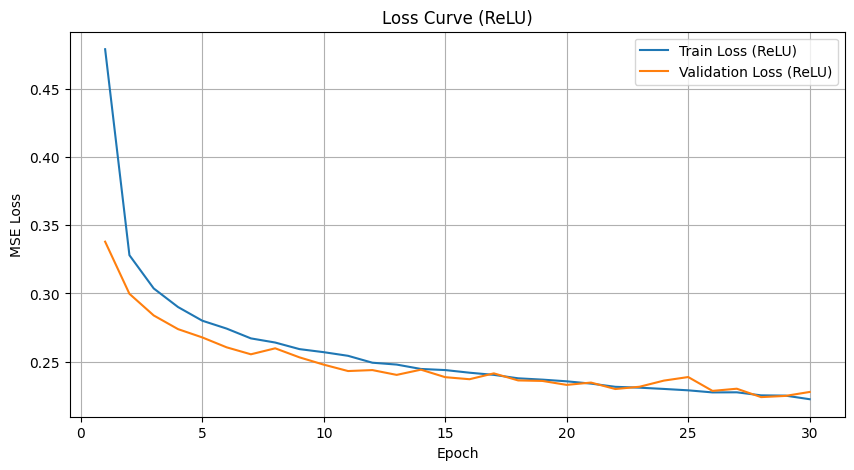


===== Test 성능 (ReLU 모델) ====
Test MSE:      0.2428
Test R² Score: 0.7463


In [ ]:
# 모델과 Trainer 생성
myModel_relu = CustomNetwork(
    input_dim=8, hidden_dim=128, output_dim=1, activation=nn.ReLU
).cuda()

myTrainer = Trainer(learning_rate=0.001, num_epochs=30)

# 학습 실행
print("=== ReLU 모델 학습 시작 ===")
train_losses_relu, val_losses_relu = myTrainer.train(myModel_relu, train_dataloader, val_dataloader)
print("=== ReLU 모델 학습 완료 ===")

# Loss Curve 시각화
plt.figure(figsize=(10, 5))
plt.plot(range(1, len(train_losses_relu)+1), train_losses_relu, label='Train Loss (ReLU)')
plt.plot(range(1, len(val_losses_relu)+1),   val_losses_relu,   label='Validation Loss (ReLU)')

plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('Loss Curve (ReLU)')

plt.legend()
plt.grid(True)
plt.show()

# Test 성능 평가
test_mse_relu, test_r2_relu = evaluate(myModel_relu, test_dataloader)

print(f"\n===== Test 성능 (ReLU 모델) ====")
print(f"Test MSE:      {test_mse_relu:.4f}")
print(f"Test R² Score: {test_r2_relu:.4f}")

### 2. Tanh 활성화 함수 모델



=== Tanh 모델 학습 시작 ===
Epoch [  1/30]  Train Loss: 0.3876  Val Loss: 0.3297
Epoch [  5/30]  Train Loss: 0.3040  Val Loss: 0.2918
Epoch [ 10/30]  Train Loss: 0.2849  Val Loss: 0.2727
Epoch [ 15/30]  Train Loss: 0.2740  Val Loss: 0.2672
Epoch [ 20/30]  Train Loss: 0.2627  Val Loss: 0.2572
Epoch [ 25/30]  Train Loss: 0.2541  Val Loss: 0.2518
Epoch [ 30/30]  Train Loss: 0.2499  Val Loss: 0.2438
=== Tanh 모델 학습 완료 ===


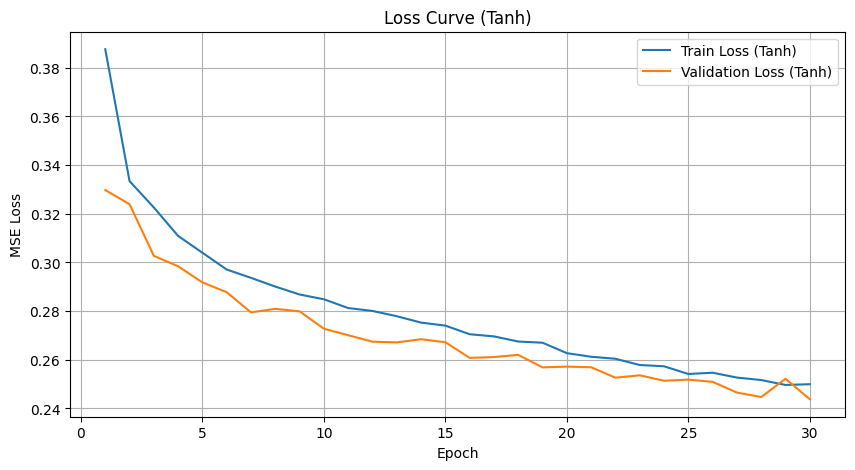


===== Test 성능 (Tanh 모델) ====
Test MSE:      0.2561
Test R² Score: 0.7323


In [ ]:
# Tanh 활성화 함수를 사용한 모델 생성
myModel_tanh = CustomNetwork(
    input_dim=8, hidden_dim=128, output_dim=1, activation=nn.Tanh
).cuda()

# Trainer 생성
myTrainer_tanh = Trainer(learning_rate=0.001, num_epochs=30)

# 학습 실행
print("\n=== Tanh 모델 학습 시작 ===")
train_losses_tanh, val_losses_tanh = myTrainer_tanh.train(myModel_tanh, train_dataloader, val_dataloader)
print("=== Tanh 모델 학습 완료 ===")

# Loss Curve 시각화
plt.figure(figsize=(10, 5))
plt.plot(range(1, len(train_losses_tanh)+1), train_losses_tanh, label='Train Loss (Tanh)')
plt.plot(range(1, len(val_losses_tanh)+1),   val_losses_tanh,   label='Validation Loss (Tanh)')

plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('Loss Curve (Tanh)')

plt.legend()
plt.grid(True)
plt.show()

# Test 성능 평가
test_mse_tanh, test_r2_tanh = evaluate(myModel_tanh, test_dataloader)

print(f"\n===== Test 성능 (Tanh 모델) ====")
print(f"Test MSE:      {test_mse_tanh:.4f}")
print(f"Test R² Score: {test_r2_tanh:.4f}")

### 3. Sigmoid 활성화 함수 모델



=== Sigmoid 모델 학습 시작 ===
Epoch [  1/30]  Train Loss: 0.6274  Val Loss: 0.3990
Epoch [  5/30]  Train Loss: 0.3417  Val Loss: 0.3258
Epoch [ 10/30]  Train Loss: 0.3288  Val Loss: 0.3135
Epoch [ 15/30]  Train Loss: 0.3152  Val Loss: 0.2996
Epoch [ 20/30]  Train Loss: 0.3021  Val Loss: 0.2874
Epoch [ 25/30]  Train Loss: 0.2935  Val Loss: 0.2814
Epoch [ 30/30]  Train Loss: 0.2887  Val Loss: 0.2767
=== Sigmoid 모델 학습 완료 ===


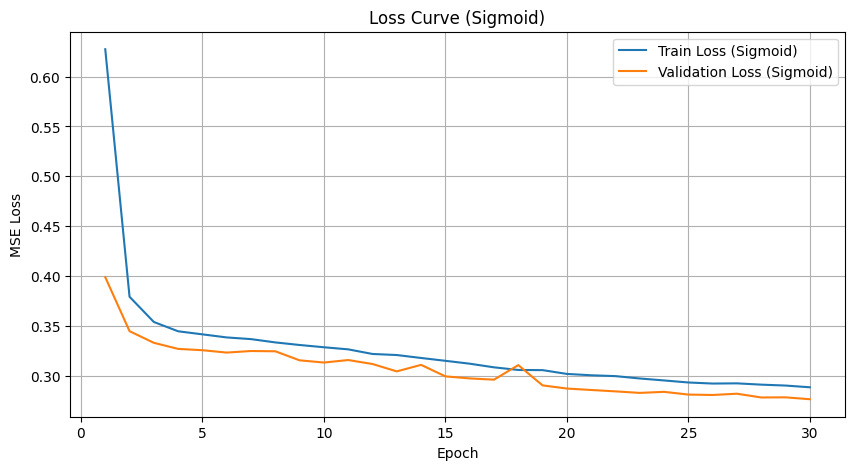


===== Test 성능 (Sigmoid 모델) ====
Test MSE:      0.2967
Test R² Score: 0.6899


In [ ]:
# Sigmoid 활성화 함수를 사용한 모델 생성
myModel_sigmoid = CustomNetwork(
    input_dim=8, hidden_dim=128, output_dim=1, activation=nn.Sigmoid
).cuda()

# Trainer 생성
myTrainer_sigmoid = Trainer(learning_rate=0.001, num_epochs=30)

# 학습 실행
print("\n=== Sigmoid 모델 학습 시작 ===")
train_losses_sigmoid, val_losses_sigmoid = myTrainer_sigmoid.train(myModel_sigmoid, train_dataloader, val_dataloader)
print("=== Sigmoid 모델 학습 완료 ===")

# Loss Curve 시각화
plt.figure(figsize=(10, 5))
plt.plot(range(1, len(train_losses_sigmoid)+1), train_losses_sigmoid, label='Train Loss (Sigmoid)')
plt.plot(range(1, len(val_losses_sigmoid)+1),   val_losses_sigmoid,   label='Validation Loss (Sigmoid)')

plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('Loss Curve (Sigmoid)')

plt.legend()
plt.grid(True)
plt.show()

# Test 성능 평가
test_mse_sigmoid, test_r2_sigmoid = evaluate(myModel_sigmoid, test_dataloader)

print(f"\n===== Test 성능 (Sigmoid 모델) ====")
print(f"Test MSE:      {test_mse_sigmoid:.4f}")
print(f"Test R² Score: {test_r2_sigmoid:.4f}")

### 4. GELU 활성화 함수 모델



=== GELU 모델 학습 시작 ===
Epoch [  1/30]  Train Loss: 0.4786  Val Loss: 0.3385
Epoch [  5/30]  Train Loss: 0.2933  Val Loss: 0.2758
Epoch [ 10/30]  Train Loss: 0.2741  Val Loss: 0.2621
Epoch [ 15/30]  Train Loss: 0.2708  Val Loss: 0.2591
Epoch [ 20/30]  Train Loss: 0.2675  Val Loss: 0.2587
Epoch [ 25/30]  Train Loss: 0.2628  Val Loss: 0.2544
Epoch [ 30/30]  Train Loss: 0.2572  Val Loss: 0.2538
=== GELU 모델 학습 완료 ===


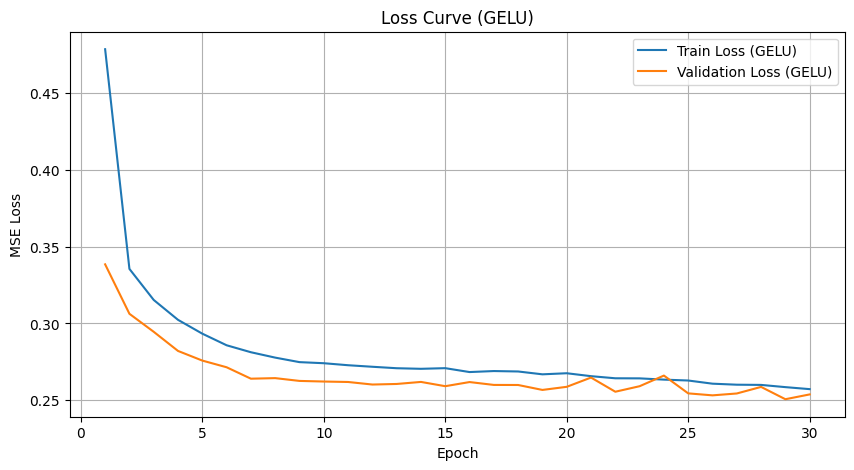


===== Test 성능 (GELU 모델) ====
Test MSE:      0.2671
Test R² Score: 0.7209


In [ ]:
# GELU 활성화 함수를 사용한 모델 생성
myModel_gelu = CustomNetwork(
    input_dim=8, hidden_dim=128, output_dim=1, activation=nn.GELU
).cuda()

# Trainer 생성
myTrainer_gelu = Trainer(learning_rate=0.001, num_epochs=30)

# 학습 실행
print("\n=== GELU 모델 학습 시작 ===")
train_losses_gelu, val_losses_gelu = myTrainer_gelu.train(myModel_gelu, train_dataloader, val_dataloader)
print("=== GELU 모델 학습 완료 ===")

# Loss Curve 시각화
plt.figure(figsize=(10, 5))
plt.plot(range(1, len(train_losses_gelu)+1), train_losses_gelu, label='Train Loss (GELU)')
plt.plot(range(1, len(val_losses_gelu)+1),   val_losses_gelu,   label='Validation Loss (GELU)')

plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('Loss Curve (GELU)')

plt.legend()
plt.grid(True)
plt.show()

# Test 성능 평가
test_mse_gelu, test_r2_gelu = evaluate(myModel_gelu, test_dataloader)

print(f"\n===== Test 성능 (GELU 모델) ====")
print(f"Test MSE:      {test_mse_gelu:.4f}")
print(f"Test R² Score: {test_r2_gelu:.4f}")

### 5. 사용자 정의 LogReLU 활성화 함수 모델

**수식:** $f(x) = \log(1 + \max(0, x))$

음수 입력은 0처리, 양수 입력에 대해서는 $log (1+x)$ 처리하여, 큰 양수 값(이상치)에 대해 둔감하게 반응


=== LogReLU 모델 학습 시작 ===
Epoch [  1/30]  Train Loss: 0.4925  Val Loss: 0.3325
Epoch [  5/30]  Train Loss: 0.2763  Val Loss: 0.2635
Epoch [ 10/30]  Train Loss: 0.2520  Val Loss: 0.2456
Epoch [ 15/30]  Train Loss: 0.2372  Val Loss: 0.2351
Epoch [ 20/30]  Train Loss: 0.2295  Val Loss: 0.2267
Epoch [ 25/30]  Train Loss: 0.2213  Val Loss: 0.2260
Epoch [ 30/30]  Train Loss: 0.2161  Val Loss: 0.2206
=== LogReLU 모델 학습 완료 ===


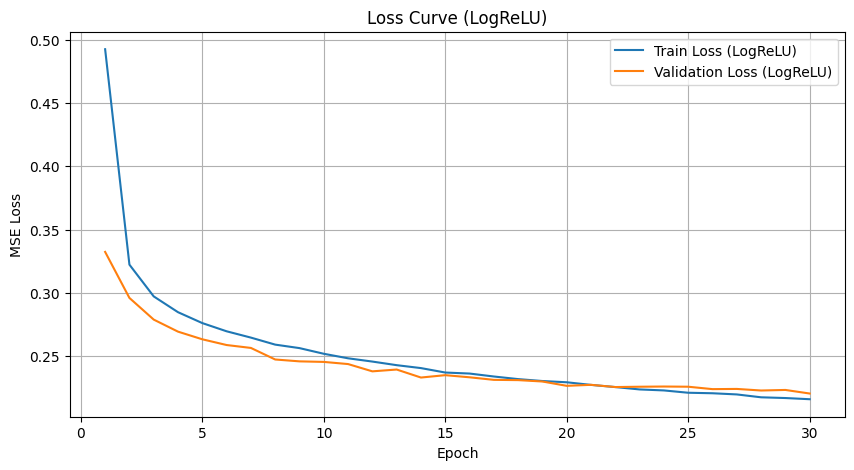


===== Test 성능 (LogReLU 모델) ====
Test MSE:      0.2366
Test R² Score: 0.7527


In [ ]:
class LogReLU(nn.Module):
    def forward(self, x):
        return torch.log(1 + F.relu(x))

# LogReLU 활성화 함수를 사용한 모델 생성
myModel_logrelu = CustomNetwork(
    input_dim=8, hidden_dim=128, output_dim=1, activation=LogReLU
).cuda()

# Trainer 생성
myTrainer_logrelu = Trainer(learning_rate=0.001, num_epochs=30)

# 학습 실행
print("\n=== LogReLU 모델 학습 시작 ===")
train_losses_logrelu, val_losses_logrelu = myTrainer_logrelu.train(myModel_logrelu, train_dataloader, val_dataloader)
print("=== LogReLU 모델 학습 완료 ===")

# Loss Curve 시각화
plt.figure(figsize=(10, 5))
plt.plot(range(1, len(train_losses_logrelu)+1), train_losses_logrelu, label='Train Loss (LogReLU)')
plt.plot(range(1, len(val_losses_logrelu)+1),   val_losses_logrelu,   label='Validation Loss (LogReLU)')

plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('Loss Curve (LogReLU)')

plt.legend()
plt.grid(True)
plt.show()

# Test 성능 평가
test_mse_logrelu, test_r2_logrelu = evaluate(myModel_logrelu, test_dataloader)

print(f"\n===== Test 성능 (LogReLU 모델) ====")
print(f"Test MSE:      {test_mse_logrelu:.4f}")
print(f"Test R² Score: {test_r2_logrelu:.4f}")